# Análisis de estados financieros con Python (NIIF + yfinance)

## Librerías

In [19]:
import textwrap
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as efectos
import seaborn as sns
import yfinance as yf
from matplotlib.ticker import PercentFormatter
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from openpyxl.drawing.image import Image
from openpyxl.styles import Font
from openpyxl.styles import Alignment
warnings.filterwarnings("ignore")

## 0. Configuración

In [20]:
# ---------- 0. CONFIGURACIÓN ----------
ticker = "CIBEST.cl"
año_inicio = 2022
año_fin = 2025
escala = 1_000_000                    # cifras en millones
simbolo = "$"                         # símbolo de moneda
archivo = ticker.replace(".", "_")    # nombre base de los archivos de salida

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", None)

# Formato de dinero: $1,234.5 y -$365.0 (d = decimales)
dinero = lambda v, d=1: f"{'-' if v < 0 else ''}{simbolo}{abs(v):,.{d}f}"

## 1. Descarga de datos

In [21]:
# ---------- 1. DESCARGA ----------
empresa = yf.Ticker(ticker)
resultados = empresa.financials
balance = empresa.balance_sheet
flujo = empresa.cashflow

# Juntamos los tres estados en una sola tabla
d = pd.concat([resultados, balance, flujo])
d = d[~d.index.duplicated()]                                   # cuentas repetidas entre estados

# Fechas de cierre originales dentro del rango (para revisar cierres repetidos y el mes fiscal)
fechas_cierre = pd.to_datetime(d.columns)
fechas_cierre = fechas_cierre[(fechas_cierre.year >= año_inicio) & (fechas_cierre.year <= año_fin)]
años_repetidos = fechas_cierre.year[fechas_cierre.year.duplicated()].unique()
meses_cierre = fechas_cierre.month.unique()

d = d.T.groupby(pd.to_datetime(d.columns).year).first().T      # columnas = años (antiguo -> reciente)
d = d.loc[:, (d.columns >= año_inicio) & (d.columns <= año_fin)]
d = d.dropna(axis=1, how="all")                                # años sin datos

# Datos generales y de mercado (si yfinance falla, seguimos sin ellos)
try:
    info = empresa.info
except Exception:
    info = {}
nombre_empresa = info.get("longName") or ticker
sector = info.get("sector") or "No disponible"
industria = info.get("industry") or "No disponible"
moneda = info.get("financialCurrency") or ""          # moneda de los estados financieros
moneda_cot = info.get("currency") or ""               # moneda en la que cotiza la acción

### Función buscar y tipo de empresa

In [22]:
# Única función del proyecto: busca una cuenta por sus posibles nombres en yfinance.
# Toma el primer nombre que exista y llena sus años vacíos con los siguientes.
def buscar(*nombres):
    fila = pd.Series(np.nan, index=d.columns)
    for nombre in nombres:
        if nombre in d.index:
            fila = fila.fillna(d.loc[nombre])
    return fila


# ¿Es financiera (banco, fintech, aseguradora)? Por el sector o porque sus ingresos por intereses
# superan a sus ingresos totales (en bancos, yfinance reporta los ingresos ya netos de intereses).
# Se define aquí porque cambia cómo se completan algunas cuentas y cómo se interpretan.
interes_ultimo = buscar("Interest Income").iloc[-1]
ingresos_ultimo = buscar("Total Revenue", "Operating Revenue").iloc[-1]
es_fin = ("Financial" in sector) or (interes_ultimo > ingresos_ultimo)

## 2. Estados financieros en orden NIIF

In [23]:
# ---------- 2. ESTADOS FINANCIEROS EN ORDEN NORMATIVO (NIIF) ----------
er = pd.DataFrame({
    "Ingresos": buscar("Total Revenue", "Operating Revenue"),
    "Costo de ventas": buscar("Cost Of Revenue", "Reconciled Cost Of Revenue"),
    "UTILIDAD BRUTA": buscar("Gross Profit"),
    "Gastos operacionales": buscar("Operating Expense"),
    "UTILIDAD OPERACIONAL": buscar("Operating Income", "Total Operating Income As Reported", "EBIT"),
    "Ingresos financieros": buscar("Interest Income", "Interest Income Non Operating"),
    "Gastos financieros": buscar("Interest Expense", "Interest Expense Non Operating", "Interest Paid Cfo"),
    "UTILIDAD ANTES DE IMPUESTOS": buscar("Pretax Income"),
    "Impuesto de renta": buscar("Tax Provision"),
    "UTILIDAD NETA": buscar("Net Income Common Stockholders", "Net Income",
                            "Net Income From Continuing Operation Net Minority Interest",
                            "Net Income Continuous Operations"),
}).T

bg = pd.DataFrame({
    "Efectivo y equivalentes": buscar("Cash And Cash Equivalents"),
    "Cuentas por cobrar": buscar("Accounts Receivable", "Receivables"),
    "Inventarios": buscar("Inventory"),
    "TOTAL ACTIVO CORRIENTE": buscar("Current Assets"),
    "Propiedad, planta y equipo": buscar("Net PPE"),
    "TOTAL ACTIVO NO CORRIENTE": buscar("Total Non Current Assets"),
    "TOTAL ACTIVOS": buscar("Total Assets"),
    "Cuentas por pagar": buscar("Accounts Payable", "Payables", "Payables And Accrued Expenses"),
    "Deuda financiera corriente": buscar("Current Debt And Capital Lease Obligation", "Current Debt"),
    "TOTAL PASIVO CORRIENTE": buscar("Current Liabilities"),
    "Deuda financiera no corriente": buscar("Long Term Debt And Capital Lease Obligation", "Long Term Debt"),
    "TOTAL PASIVO NO CORRIENTE": buscar("Total Non Current Liabilities Net Minority Interest"),
    "TOTAL PASIVOS": buscar("Total Liabilities Net Minority Interest"),
    "Capital": buscar("Common Stock"),
    "Ganancias acumuladas": buscar("Retained Earnings"),
    "TOTAL PATRIMONIO": buscar("Total Equity Gross Minority Interest", "Stockholders Equity"),
}).T

fc = pd.DataFrame({
    "Utilidad neta": buscar("Net Income From Continuing Operations"),
    "Depreciación y amortización": buscar("Depreciation And Amortization",
                                          "Depreciation Amortization Depletion", "Reconciled Depreciation"),
    "Cambio en capital de trabajo": buscar("Change In Working Capital"),
    "FLUJO DE OPERACIÓN": buscar("Operating Cash Flow", "Cash Flow From Continuing Operating Activities"),
    "CAPEX": buscar("Capital Expenditure", "Purchase Of PPE"),
    "FLUJO DE INVERSIÓN": buscar("Investing Cash Flow"),
    "Dividendos pagados": buscar("Cash Dividends Paid"),
    "FLUJO DE FINANCIACIÓN": buscar("Financing Cash Flow"),
    "Efectivo inicial": buscar("Beginning Cash Position"),
    "EFECTIVO FINAL": buscar("End Cash Position"),
}).T

# Copias de lo que trajo yfinance, para saber al final qué se calculó
er_original = er.copy()
bg_original = bg.copy()
fc_original = fc.copy()

## 3. Completar cuentas con identidades contables

In [24]:
# ---------- 3. COMPLETAR CUENTAS VACÍAS CON IDENTIDADES CONTABLES ----------
# Solo se llenan los años vacíos; si yfinance trae el dato, se respeta.

# Estado de resultados
er.loc["Gastos financieros"] = er.loc["Gastos financieros"].abs()     # a veces viene negativo
er.loc["Costo de ventas"] = er.loc["Costo de ventas"].fillna(er.loc["Ingresos"] - er.loc["UTILIDAD BRUTA"])
er.loc["UTILIDAD BRUTA"] = er.loc["UTILIDAD BRUTA"].fillna(er.loc["Ingresos"] - er.loc["Costo de ventas"].abs())
if es_fin:
    # En financieras los intereses SON la operación (y yfinance ya los descuenta de los ingresos):
    # la utilidad operacional es la utilidad antes de impuestos. Restarle los intereses otra vez
    # daría una utilidad operacional negativa falsa.
    er.loc["UTILIDAD OPERACIONAL"] = er.loc["UTILIDAD OPERACIONAL"].fillna(er.loc["UTILIDAD ANTES DE IMPUESTOS"])
else:
    er.loc["UTILIDAD OPERACIONAL"] = er.loc["UTILIDAD OPERACIONAL"].fillna(
        er.loc["Ingresos"] - buscar("Total Expenses").abs())
    er.loc["UTILIDAD OPERACIONAL"] = er.loc["UTILIDAD OPERACIONAL"].fillna(
        er.loc["UTILIDAD ANTES DE IMPUESTOS"] + er.loc["Gastos financieros"].fillna(0)
        - er.loc["Ingresos financieros"].fillna(0))
er.loc["Gastos operacionales"] = er.loc["Gastos operacionales"].fillna(
    er.loc["UTILIDAD BRUTA"] - er.loc["UTILIDAD OPERACIONAL"])

# Balance
bg.loc["Efectivo y equivalentes"] = bg.loc["Efectivo y equivalentes"].fillna(
    buscar("Cash Cash Equivalents And Short Term Investments") - buscar("Other Short Term Investments").fillna(0))

# Identidades: (cuenta a llenar, cuenta A, cuenta B, signo)  ->  cuenta = A + signo x B
identidades = [
    ("TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO", +1),
    ("TOTAL PASIVOS", "TOTAL ACTIVOS", "TOTAL PATRIMONIO", -1),
    ("TOTAL PATRIMONIO", "TOTAL ACTIVOS", "TOTAL PASIVOS", -1),
    ("TOTAL ACTIVO CORRIENTE", "TOTAL ACTIVOS", "TOTAL ACTIVO NO CORRIENTE", -1),
    ("TOTAL ACTIVO NO CORRIENTE", "TOTAL ACTIVOS", "TOTAL ACTIVO CORRIENTE", -1),
    ("TOTAL PASIVO CORRIENTE", "TOTAL PASIVOS", "TOTAL PASIVO NO CORRIENTE", -1),
    ("TOTAL PASIVO NO CORRIENTE", "TOTAL PASIVOS", "TOTAL PASIVO CORRIENTE", -1),
]
for cuenta, a, b, signo in identidades:
    bg.loc[cuenta] = bg.loc[cuenta].fillna(bg.loc[a] + signo * bg.loc[b])

# Si el corriente sigue vacío, se suma con sus componentes
componentes_ac = pd.DataFrame([
    bg.loc["Efectivo y equivalentes"],
    buscar("Other Short Term Investments"),
    bg.loc["Cuentas por cobrar"],
    bg.loc["Inventarios"],
    buscar("Prepaid Assets"),
    buscar("Other Current Assets"),
])
componentes_pc = pd.DataFrame([
    bg.loc["Cuentas por pagar"],
    bg.loc["Deuda financiera corriente"],
    buscar("Income Tax Payable"),
    buscar("Current Provisions"),
    buscar("Other Current Liabilities"),
])
# En financieras no se hace: su balance no se divide en corriente / no corriente
# (los depósitos de clientes son pasivos de corto plazo y quedarían mal clasificados)
if not es_fin:
    bg.loc["TOTAL ACTIVO CORRIENTE"] = bg.loc["TOTAL ACTIVO CORRIENTE"].fillna(componentes_ac.sum(min_count=1))
    bg.loc["TOTAL PASIVO CORRIENTE"] = bg.loc["TOTAL PASIVO CORRIENTE"].fillna(componentes_pc.sum(min_count=1))

# Repetimos las identidades para llenar lo que quedó pendiente
for cuenta, a, b, signo in identidades:
    bg.loc[cuenta] = bg.loc[cuenta].fillna(bg.loc[a] + signo * bg.loc[b])

bg.loc["Deuda financiera no corriente"] = bg.loc["Deuda financiera no corriente"].fillna(
    buscar("Total Debt") - bg.loc["Deuda financiera corriente"].fillna(0))
bg.loc["TOTAL PASIVO + PATRIMONIO"] = bg.loc["TOTAL PASIVOS"] + bg.loc["TOTAL PATRIMONIO"]

# Flujo de caja
fc.loc["Utilidad neta"] = fc.loc["Utilidad neta"].fillna(er.loc["UTILIDAD NETA"])
fc.loc["Depreciación y amortización"] = fc.loc["Depreciación y amortización"].fillna(
    buscar("EBITDA", "Normalized EBITDA") - er.loc["UTILIDAD OPERACIONAL"])
fc.loc["CAPEX"] = fc.loc["CAPEX"].fillna(buscar("Free Cash Flow") - fc.loc["FLUJO DE OPERACIÓN"])

# Datos calculados: estaban vacíos en yfinance y ahora tienen valor -> {cuenta: [años]}
calculados = {}
for tabla_original, tabla_final in [(er_original, er), (bg_original, bg), (fc_original, fc)]:
    llenados = tabla_original.isna() & tabla_final.loc[tabla_original.index].notna()
    for cuenta in llenados.index:
        años_llenados = [str(año) for año in llenados.columns if llenados.loc[cuenta, año]]
        if años_llenados:
            calculados[cuenta] = años_llenados

# Quitamos las cuentas que la empresa no tiene (vacías en todos los años)
er = er.dropna(how="all")
bg = bg.dropna(how="all")
fc = fc.dropna(how="all")

## 4. Análisis horizontal y vertical

In [25]:
# ---------- 4. ANÁLISIS HORIZONTAL Y VERTICAL ----------
# Horizontal: variación % contra el año anterior (se divide por el valor absoluto
# para que el signo tenga sentido cuando el año anterior es negativo)
h_er = ((er - er.shift(axis=1)) / er.shift(axis=1).abs() * 100).iloc[:, 1:]
h_bg = ((bg - bg.shift(axis=1)) / bg.shift(axis=1).abs() * 100).iloc[:, 1:]

# Vertical: resultados como % de ingresos, balance como % del activo total
v_er = er / er.loc["Ingresos"] * 100
v_bg = bg / bg.loc["TOTAL ACTIVOS"] * 100

## 5. Indicadores financieros

In [26]:
# ---------- 5. INDICADORES FINANCIEROS ----------
# Variables con nombre corto (reindex evita errores si una cuenta no existe)
ventas = er.loc["Ingresos"]
costo = er.reindex(["Costo de ventas"]).iloc[0].abs()
u_bruta = er.reindex(["UTILIDAD BRUTA"]).iloc[0]
u_oper = er.reindex(["UTILIDAD OPERACIONAL"]).iloc[0]
u_neta = er.reindex(["UTILIDAD NETA"]).iloc[0]
g_fin = er.reindex(["Gastos financieros"]).iloc[0].abs()
ing_fin = er.reindex(["Ingresos financieros"]).iloc[0]

efectivo = bg.reindex(["Efectivo y equivalentes"]).iloc[0]
cartera = bg.reindex(["Cuentas por cobrar"]).iloc[0]
inventario = bg.reindex(["Inventarios"]).iloc[0].fillna(0)
ac = bg.reindex(["TOTAL ACTIVO CORRIENTE"]).iloc[0]
at = bg.loc["TOTAL ACTIVOS"]
proveedores = bg.reindex(["Cuentas por pagar"]).iloc[0]
pc = bg.reindex(["TOTAL PASIVO CORRIENTE"]).iloc[0]
pt = bg.reindex(["TOTAL PASIVOS"]).iloc[0]
patrimonio = bg.reindex(["TOTAL PATRIMONIO"]).iloc[0]
deuda_corriente = bg.reindex(["Deuda financiera corriente"]).iloc[0].fillna(0)
deuda_largo = bg.reindex(["Deuda financiera no corriente"]).iloc[0].fillna(0)
deuda = deuda_corriente + deuda_largo

# Saldos promedio (inicio + fin) / 2 para ROE, ROA y DuPont; el primer año usa el de cierre
at_prom = ((at + at.shift()) / 2).fillna(at)
patrimonio_prom = ((patrimonio + patrimonio.shift()) / 2).fillna(patrimonio)

depreciacion = fc.reindex(["Depreciación y amortización"]).iloc[0].abs()
ebitda = u_oper + depreciacion
f_oper = fc.reindex(["FLUJO DE OPERACIÓN"]).iloc[0]
capex = fc.reindex(["CAPEX"]).iloc[0].abs()
fcl = f_oper - capex                                       # flujo de caja libre
dividendos = fc.reindex(["Dividendos pagados"]).iloc[0].abs()

# Si no hay costo de ventas (gastos por naturaleza), los días se calculan sobre el total de costos y gastos
costo_dias = costo.fillna((ventas - u_oper).abs())

ind = pd.DataFrame({
    # Liquidez
    "Razón corriente (veces)": ac / pc,
    "Prueba ácida (veces)": (ac - inventario) / pc,
    "Capital de trabajo (millones)": (ac - pc) / escala,
    # Endeudamiento
    "Endeudamiento (%)": pt / at * 100,
    "Pasivo / Patrimonio (veces)": pt / patrimonio,
    "Deuda neta / EBITDA (veces)": (deuda - efectivo) / ebitda,
    "Cobertura de intereses (veces)": u_oper / g_fin,
    # Rentabilidad
    "Margen bruto (%)": u_bruta / ventas * 100,
    "Margen operacional (%)": u_oper / ventas * 100,
    "Margen EBITDA (%)": ebitda / ventas * 100,
    "Margen neto (%)": u_neta / ventas * 100,
    "ROA (%)": u_neta / at_prom * 100,
    "ROE (%)": u_neta / patrimonio_prom * 100,
    # Eficiencia
    "Días de cartera": cartera / ventas * 365,
    "Días de inventario": inventario / costo_dias * 365,
    "Días de proveedores": proveedores / costo_dias * 365,
    # Generación de caja
    "Flujo operación / Utilidad neta (veces)": f_oper / u_neta,
    "Flujo de caja libre (millones)": fcl / escala,
    "Dividendos / Utilidad neta (%)": dividendos / u_neta.where(u_neta > 0) * 100,
    # DuPont: ROE = margen neto x rotación de activos x multiplicador de capital
    "DuPont - Rotación de activos (veces)": ventas / at_prom,
    "DuPont - Multiplicador de capital (veces)": at_prom / patrimonio_prom,
}).T
ind.loc["Ciclo de efectivo (días)"] = ind.loc["Días de cartera"] + ind.loc["Días de inventario"] - ind.loc["Días de proveedores"]

ind = ind.replace([np.inf, -np.inf], np.nan)              # divisiones por cero
# En financieras estos indicadores no tienen sentido económico: se quitan
indicadores_no_fin = ["Razón corriente (veces)", "Prueba ácida (veces)", "Capital de trabajo (millones)",
                      "Margen bruto (%)", "Margen EBITDA (%)", "Deuda neta / EBITDA (veces)",
                      "Cobertura de intereses (veces)", "Días de cartera", "Días de inventario",
                      "Días de proveedores", "Ciclo de efectivo (días)"]
if es_fin:
    ind = ind.drop(index=indicadores_no_fin)
no_aplican = list(ind.index[ind.isna().all(axis=1)])      # indicadores sin datos en ningún año
ind = ind.dropna(how="all")

## 6. Indicadores de mercado

In [27]:
# ---------- 6. INDICADORES DE MERCADO (VALORACIÓN) ----------
# Se toman de Yahoo: si cotiza en otra moneda (ej. COP) y reporta en USD, calcularlos a mano daría errores
precio = info.get("currentPrice") or info.get("regularMarketPrice") or np.nan
capitalizacion = info.get("marketCap") or np.nan
pe = info.get("trailingPE") or np.nan                 # precio / utilidad por acción
pb = info.get("priceToBook") or np.nan                # precio / valor en libros
ev_ebitda = info.get("enterpriseToEbitda") or np.nan
beta = info.get("beta") or np.nan

mercado = pd.Series({
    f"Precio ({moneda_cot})": precio,
    f"Capitalización (millones {moneda_cot})": capitalizacion / escala,
    "P/E (veces)": pe,
    "P/B (veces)": pb,
    "EV/EBITDA (veces)": ev_ebitda,
    "Beta": beta,
})

## 7. Tablas de resultados

In [28]:
# ---------- 7. MOSTRAR TABLAS ----------
# Unidad de cada fila según su nombre: % , x (veces), $ (dinero) o n (número)
unidades = {}
for fila in list(ind.index) + list(mercado.index):
    if "(%)" in fila:
        unidades[fila] = "%"
    elif "(veces)" in fila:
        unidades[fila] = "x"
    elif "millones" in fila or "Precio" in fila:
        unidades[fila] = "$"
    else:
        unidades[fila] = "n"

# Indicadores y mercado como texto, cada uno con su unidad
ind_mostrar = ind.copy().astype(object)
for fila in ind.index:
    for año in ind.columns:
        valor = ind.loc[fila, año]
        if pd.isna(valor):
            texto_valor = ""
        elif unidades[fila] == "%":
            texto_valor = f"{valor:,.2f}%"
        elif unidades[fila] == "x":
            texto_valor = f"{valor:,.2f}x"
        elif unidades[fila] == "$":
            texto_valor = dinero(valor)
        else:
            texto_valor = f"{valor:,.0f}"           # días
        ind_mostrar.loc[fila, año] = texto_valor

mercado_mostrar = mercado.copy().astype(object)
for fila in mercado.index:
    valor = mercado[fila]
    if pd.isna(valor):
        mercado_mostrar[fila] = "No disponible"
    elif unidades[fila] == "x":
        mercado_mostrar[fila] = f"{valor:,.2f}x"
    elif unidades[fila] == "$":
        mercado_mostrar[fila] = dinero(valor)
    else:
        mercado_mostrar[fila] = f"{valor:,.2f}"

print(f"\n===== {nombre_empresa} ({ticker})  {año_inicio}-{año_fin}  ·  cifras en millones de {moneda} =====")
print("\nESTADO DE RESULTADOS\n", (er / escala).to_string(float_format=dinero))
print("\nBALANCE GENERAL\n", (bg / escala).to_string(float_format=dinero))
print("\nFLUJO DE CAJA\n", (fc / escala).to_string(float_format=dinero))
print("\nHORIZONTAL - RESULTADOS (variación %)\n", h_er.to_string(float_format=lambda v: f"{v:,.2f}%"))
print("\nHORIZONTAL - BALANCE (variación %)\n", h_bg.to_string(float_format=lambda v: f"{v:,.2f}%"))
print("\nVERTICAL - RESULTADOS (% de ingresos)\n", v_er.to_string(float_format=lambda v: f"{v:,.2f}%"))
print("\nVERTICAL - BALANCE (% del activo)\n", v_bg.to_string(float_format=lambda v: f"{v:,.2f}%"))
print("\nINDICADORES\n", ind_mostrar.to_string())
print("\nMERCADO\n", mercado_mostrar.to_string())


===== Grupo Cibest S.A. (CIBEST.cl)  2022-2025  ·  cifras en millones de COP =====

ESTADO DE RESULTADOS
                                      2022          2023          2024          2025
Ingresos                    $24,249,105.0 $26,633,441.0 $26,228,770.0 $27,567,992.0
UTILIDAD OPERACIONAL         $9,744,786.0  $7,522,671.0  $8,490,248.0  $9,759,305.0
Ingresos financieros        $25,434,247.0 $33,670,382.0 $31,188,803.0 $30,051,420.0
Gastos financieros           $8,442,470.0 $15,430,183.0 $13,687,660.0 $12,061,226.0
UTILIDAD ANTES DE IMPUESTOS  $9,744,786.0  $7,522,671.0  $8,490,248.0  $9,759,305.0
Impuesto de renta            $2,748,421.0  $1,820,293.0  $2,379,852.0  $2,810,966.0
UTILIDAD NETA                $6,783,490.0  $3,272,149.0  $3,352,068.0  $2,060,871.0

BALANCE GENERAL
                                         2022           2023           2024           2025
Efectivo y equivalentes        $28,771,575.0  $31,958,683.0  $27,121,151.0  $25,242,810.0
Cuentas por cobrar     

## 8. Interpretación automática

In [29]:
# ---------- 8. INTERPRETACIÓN AUTOMÁTICA ----------
# El texto se arma con los datos: si cambias el ticker o los años, la lectura cambia sola.
# Los umbrales son referencias generales, no reglas absolutas.
primero = er.columns[0]
ultimo = er.columns[-1]
anterior = er.columns[-2]
n_años = ultimo - primero

# Indicadores del último y del primer año (NaN si no existen)
ult = ind[ultimo]
pri = ind[primero]
roe_u = ult.get("ROE (%)", np.nan)
roa_u = ult.get("ROA (%)", np.nan)
mn_u = ult.get("Margen neto (%)", np.nan)
mn_p = pri.get("Margen neto (%)", np.nan)
mop_u = ult.get("Margen operacional (%)", np.nan)
mebitda_u = ult.get("Margen EBITDA (%)", np.nan)
rc_u = ult.get("Razón corriente (veces)", np.nan)
pa_u = ult.get("Prueba ácida (veces)", np.nan)
endeu_u = ult.get("Endeudamiento (%)", np.nan)
dn_u = ult.get("Deuda neta / EBITDA (veces)", np.nan)
cob_u = ult.get("Cobertura de intereses (veces)", np.nan)
rot_u = ult.get("DuPont - Rotación de activos (veces)", np.nan)
mult_u = ult.get("DuPont - Multiplicador de capital (veces)", np.nan)
calidad_u = ult.get("Flujo operación / Utilidad neta (veces)", np.nan)
payout_u = ult.get("Dividendos / Utilidad neta (%)", np.nan)
ciclo_p = pri.get("Ciclo de efectivo (días)", np.nan)
ciclo_u = ult.get("Ciclo de efectivo (días)", np.nan)
solvencia_u = patrimonio[ultimo] / at[ultimo] * 100

# es_fin (empresa financiera) se definió en la sección 1

# Crecimiento promedio anual (CAGR) y del último año
cagr = np.nan
if ventas[primero] > 0:
    cagr = ((ventas[ultimo] / ventas[primero]) ** (1 / n_años) - 1) * 100
crec_ult = h_er.loc["Ingresos", ultimo]

# Crecimiento de la utilidad: promedio si es positiva al inicio y al final; si no, el del último año
crec_un = np.nan
if u_neta[anterior] > 0 and u_neta[ultimo] > 0:
    crec_un = h_er.loc["UTILIDAD NETA", ultimo]
crec_util = crec_un
if u_neta[primero] > 0 and u_neta[ultimo] > 0:
    crec_util = ((u_neta[ultimo] / u_neta[primero]) ** (1 / n_años) - 1) * 100

# PEG = P/E dividido por el crecimiento de la utilidad
peg = np.nan
if pe > 0 and crec_util > 0:
    peg = pe / crec_util

### Párrafos de la interpretación

In [30]:
lectura = []

# A. Crecimiento
if cagr > 15:
    nivel = "alto"
elif cagr > 5:
    nivel = "moderado"
elif cagr >= 0:
    nivel = "bajo"
else:
    nivel = "negativo"
if crec_ult < cagr - 5:
    ritmo = "se está desacelerando"
elif crec_ult > cagr + 5:
    ritmo = "se está acelerando"
else:
    ritmo = "va en línea con su tendencia"
txt = f"CRECIMIENTO: entre {primero} y {ultimo} los ingresos crecieron {cagr:.1f}% anual ({nivel}). "
txt += f"En {ultimo} crecieron {crec_ult:.1f}%: {ritmo}."
if pd.notna(crec_un) and crec_un > crec_ult:
    txt += f" La utilidad neta creció {crec_un:.1f}%, más que las ventas: gana eficiencia."
elif pd.notna(crec_un):
    txt += f" La utilidad neta creció {crec_un:.1f}%, menos que las ventas: los costos crecen más rápido."
lectura.append(txt)

# B. Rentabilidad
if u_neta[ultimo] < 0:
    txt = f"RENTABILIDAD: en {ultimo} hubo pérdidas (margen neto {mn_u:.1f}%)."
elif patrimonio[ultimo] <= 0:
    txt = "RENTABILIDAD: el patrimonio es negativo, así que el ROE no tiene sentido económico."
else:
    if roe_u > 15:
        nivel = "alto"
    elif roe_u > 8:
        nivel = "aceptable"
    else:
        nivel = "bajo"
    txt = f"RENTABILIDAD: ROE de {roe_u:.1f}% sobre patrimonio promedio, nivel {nivel}."
if mn_u > mn_p:
    txt += f" El margen neto mejoró de {mn_p:.1f}% en {primero} a {mn_u:.1f}% en {ultimo}."
else:
    txt += f" El margen neto empeoró de {mn_p:.1f}% en {primero} a {mn_u:.1f}% en {ultimo}."
if es_fin:
    if roa_u >= 1.5:
        nivel = "muy bueno"
    elif roa_u >= 1:
        nivel = "adecuado"
    else:
        nivel = "bajo"
    txt += f" ROA de {roa_u:.2f}%: {nivel} para una financiera (referencia: 1% o más)."
lectura.append(txt)

# C. Origen de la utilidad
if es_fin:
    margen_fin = (ing_fin[ultimo] - g_fin[ultimo]) / ing_fin[ultimo] * 100
    veces_fin = ing_fin[ultimo] / ventas[ultimo]
    txt = f"NEGOCIO FINANCIERO: sector '{sector}' ({industria}); su negocio es cobrar intereses. "
    txt += f"En {ultimo} los ingresos financieros fueron {veces_fin:.2f} veces los operativos "
    txt += f"y tras pagar intereses le quedó el {margen_fin:.1f}%."
    txt += " En financieras la utilidad operacional se toma como la utilidad antes de impuestos."
else:
    txt = f"ORIGEN DE LA UTILIDAD: margen operacional {mop_u:.1f}% y margen EBITDA {mebitda_u:.1f}%. "
    if mop_u < 0 and u_neta[ultimo] > 0:
        txt += "La operación pierde dinero y la utilidad depende de ingresos no operacionales (menos sostenible)."
    elif mop_u < 0:
        txt += "La operación pierde dinero."
    else:
        txt += "La utilidad viene del negocio principal."
lectura.append(txt)

# D. DuPont
if u_neta[ultimo] > 0 and patrimonio[ultimo] > 0:
    txt = f"DUPONT ({ultimo}): ROE {roe_u:.1f}% = margen neto {mn_u:.1f}% x rotación {rot_u:.2f} x multiplicador {mult_u:.2f}. "
    if mult_u > 4 and es_fin:
        txt += "Gran parte del ROE viene del apalancamiento, normal en una financiera que se fondea con depósitos."
    elif mult_u > 4:
        txt += "Gran parte del ROE viene del apalancamiento, lo que lo hace frágil."
    elif rot_u > 1:
        txt += "El ROE se explica por el uso eficiente de los activos."
    else:
        txt += "El ROE se explica sobre todo por el margen."
    lectura.append(txt)

# E. Liquidez y deuda (en financieras: solidez del patrimonio)
if es_fin:
    if solvencia_u >= 10:
        nivel = "razonable"
    elif solvencia_u >= 6:
        nivel = "moderado"
    else:
        nivel = "delgado"
    txt = f"SOLIDEZ: el patrimonio es el {solvencia_u:.1f}% de los activos, colchón {nivel} "
    txt += "(aproximación: la solvencia regulatoria usa activos ponderados por riesgo). "
    txt += "La razón corriente y los días de cartera no se evalúan: la 'cartera' son créditos y los pasivos incluyen depósitos."
else:
    if rc_u < 1:
        nivel = "insuficiente"
    elif rc_u < 1.5:
        nivel = "justa"
    elif rc_u <= 3:
        nivel = "holgada"
    else:
        nivel = "muy alta, posibles recursos ociosos"
    txt = f"LIQUIDEZ Y DEUDA: razón corriente {rc_u:.2f} ({nivel})."
    if rc_u - pa_u > 0.3:
        txt += f" Sin inventarios baja a {pa_u:.2f}."
    if endeu_u > 70:
        nivel = "alto"
    elif endeu_u > 50:
        nivel = "moderado"
    else:
        nivel = "bajo"
    txt += f" El {endeu_u:.1f}% de los activos se financia con pasivos ({nivel})."
    if ebitda[ultimo] <= 0:
        txt += " EBITDA negativo: Deuda neta / EBITDA no aplica."
    elif dn_u < 0:
        txt += " Tiene caja neta (más efectivo que deuda)."
    elif dn_u <= 3:
        txt += f" Deuda neta / EBITDA de {dn_u:.2f} (manejable)."
    else:
        txt += f" Deuda neta / EBITDA de {dn_u:.2f} (exigente)."
    if cob_u < 1:
        txt += f" La operación NO cubre los intereses ({cob_u:.2f} veces)."
    elif cob_u < 3:
        txt += f" La operación cubre los intereses {cob_u:.2f} veces (justo)."
    elif cob_u >= 3:
        txt += f" La operación cubre los intereses {cob_u:.2f} veces (holgado)."
lectura.append(txt)

# F. Caja
años_fcl = int(fcl.notna().sum())
años_fcl_positivos = int((fcl > 0).sum())
txt = "CAJA:"
if u_neta[ultimo] > 0 and calidad_u >= 1:
    txt += f" el flujo de operación fue {calidad_u:.2f} veces la utilidad neta: la utilidad sí se convierte en caja."
elif u_neta[ultimo] > 0 and calidad_u >= 0.7:
    txt += f" el flujo de operación fue {calidad_u:.2f} veces la utilidad neta: conversión aceptable."
elif u_neta[ultimo] > 0 and calidad_u < 0.7:
    txt += f" el flujo de operación fue solo {calidad_u:.2f} veces la utilidad neta: baja conversión en caja."
txt += f" El flujo de caja libre fue positivo en {años_fcl_positivos} de {años_fcl} años."
if pd.notna(payout_u):
    txt += f" Repartió en dividendos el {payout_u:.1f}% de la utilidad."
if es_fin:
    txt += " En financieras el flujo de operación depende del crecimiento de créditos y depósitos."
lectura.append(txt)

# G. Ciclo de efectivo
if not es_fin and pd.notna(ciclo_p) and pd.notna(ciclo_u):
    txt = f"CICLO DE EFECTIVO: pasó de {ciclo_p:.0f} a {ciclo_u:.0f} días: "
    if ciclo_u < ciclo_p:
        txt += "la empresa recupera su dinero más rápido."
    else:
        txt += "la empresa tarda más en recuperar su dinero."
    lectura.append(txt)

# H. Tendencia en todos los años (1 = más alto es mejor, -1 = más bajo es mejor)
claves = {"Margen neto (%)": 1, "ROE (%)": 1, "Endeudamiento (%)": -1}
if not es_fin:
    claves["Razón corriente (veces)"] = 1
tendencias = []
empeoran = []
for nombre_ind, direccion in claves.items():
    serie = ind.loc[nombre_ind].dropna()
    cambios = serie.diff().dropna() * direccion          # positivo = mejoró
    mejoras = int((cambios > 0).sum())
    tendencias.append(f"{nombre_ind} mejoró en {mejoras} de {len(cambios)} años")
    if mejoras == 0:
        empeoran.append(nombre_ind)
lectura.append("TENDENCIA: " + "; ".join(tendencias) + ".")

# I. Valoración
txt = "VALORACIÓN:"
if pe > 0:
    if pe < 10:
        nivel = "bajo"
    elif pe <= 25:
        nivel = "normal"
    else:
        nivel = "alto: el mercado espera mucho crecimiento"
    txt += f" P/E {pe:.1f} ({nivel})."
if peg < 1:
    txt += f" PEG {peg:.2f}: precio razonable frente al crecimiento."
elif peg <= 2:
    txt += f" PEG {peg:.2f}: precio acorde al crecimiento."
elif peg > 2:
    txt += f" PEG {peg:.2f}: el precio exige más crecimiento del que muestra."
if pd.notna(pb):
    txt += f" P/B {pb:.2f}."
if not es_fin and pd.notna(ev_ebitda):
    txt += f" EV/EBITDA {ev_ebitda:.1f}."
if beta > 1.2:
    txt += f" Beta {beta:.2f}: más volátil que el mercado."
elif beta < 0.8:
    txt += f" Beta {beta:.2f}: acción defensiva."
elif pd.notna(beta):
    txt += f" Beta {beta:.2f}: se mueve parecido al mercado."
if moneda_cot and moneda and moneda_cot != moneda:
    txt += f" Cotiza en {moneda_cot} y reporta en {moneda}: los múltiplos se toman de Yahoo."
txt += " Compararlos con empresas del mismo sector."
lectura.append(txt)

### Alertas y puntos a favor

In [31]:
# ----- Alertas: (condición, alerta, recomendación). Las comparaciones con NaN dan False -----
reglas_alerta = [
    (cagr < 0, f"Ventas cayendo {cagr:.1f}% anual",
     "Ver si la caída es del sector o de la empresa; comparar con competidores y leer el informe de gestión."),
    (u_neta[ultimo] < 0, f"Pérdidas en {ultimo}",
     "Ver si son puntuales (deterioros, extraordinarios) o recurrentes, y cuánto tiempo las aguanta con su efectivo."),
    (patrimonio[ultimo] <= 0, "Patrimonio negativo",
     "Riesgo de solvencia: revisar planes de capitalización o reestructuración de deuda."),
    (u_neta[ultimo] > 0 and roe_u < 8, f"ROE bajo ({roe_u:.1f}%)",
     "Compararlo con los TES: si rinde menos que una inversión sin riesgo, no crea valor. Usar DuPont para ver qué falla."),
    (mn_u < mn_p, "Margen neto en deterioro",
     "Usar el análisis vertical para ver qué renglón pesa cada vez más sobre los ingresos."),
    (es_fin and roa_u < 1, f"ROA bajo para una financiera ({roa_u:.2f}%)",
     "Revisar calidad de cartera (provisiones) y eficiencia (gastos frente a ingresos)."),
    (not es_fin and mop_u < 0 and u_neta[ultimo] > 0, "Utilidad que no viene de la operación",
     "Identificar de dónde salen esos ingresos y si se repetirán; valorar con la utilidad operacional."),
    (not es_fin and mop_u < 0 and u_neta[ultimo] <= 0, "Operación con pérdidas",
     "Calcular cuántos años aguanta con su efectivo y si los márgenes vienen mejorando."),
    (not es_fin and mult_u > 4 and u_neta[ultimo] > 0, "ROE muy apoyado en apalancamiento",
     "Si suben las tasas o caen las ventas el ROE cae rápido: revisar vencimientos y tasa de la deuda."),
    (not es_fin and rc_u < 1, f"Razón corriente menor a 1 ({rc_u:.2f})",
     "Revisar líneas de crédito y refinanciación. En supermercados o restaurantes puede ser normal."),
    (es_fin and solvencia_u < 6, f"Colchón de capital delgado ({solvencia_u:.1f}%)",
     "Revisar la relación de solvencia regulatoria (Superfinanciera) y si cumple el mínimo."),
    (not es_fin and endeu_u > 70, f"Endeudamiento de {endeu_u:.1f}%",
     "Separar deuda financiera (con intereses) de proveedores y revisar cuándo vence."),
    (not es_fin and ebitda[ultimo] > 0 and dn_u > 3, f"Deuda neta / EBITDA de {dn_u:.2f}",
     "Los bancos suelen exigir menos de 3-3,5 veces: revisar planes para bajar deuda o subir EBITDA."),
    (not es_fin and cob_u < 1, "Intereses no cubiertos por la operación",
     "Riesgo de impago: revisar si refinancia o vende activos para pagar intereses."),
    (u_neta[ultimo] > 0 and calidad_u < 0.7, "Baja conversión de utilidad en caja",
     "Ver si cartera o inventarios crecen más rápido que las ventas: vende pero no cobra."),
    (años_fcl_positivos < años_fcl / 2, "Flujo de caja libre negativo la mayoría de años",
     "Ver si es CAPEX de crecimiento (aceptable) o falta de caja operativa (problema)."),
    (payout_u > 100, "Dividendos mayores a la utilidad",
     "Reparte más de lo que gana: revisar si lo paga con deuda; no es sostenible."),
    (not es_fin and ciclo_u > ciclo_p, "Ciclo de efectivo más largo",
     "Comparar días de cartera, inventario y proveedores para ver cuál se alargó."),
    (peg > 2, f"Valoración exigente (PEG {peg:.2f})",
     "El precio ya descuenta mucho crecimiento: revisar si las proyecciones lo justifican."),
    (pb > 3 and roe_u < 15, "Se paga mucho por un patrimonio poco rentable",
     "Un P/B alto solo se justifica con un ROE alto y sostenible."),
]
for nombre_ind in empeoran:
    reglas_alerta.append((True, f"{nombre_ind} empeoró todos los años",
                          "Un deterioro constante preocupa más que un mal año: buscar la causa."))

# ----- Puntos a favor: (condición, texto) -----
reglas_favor = [
    (cagr > 15, f"Ventas creciendo {cagr:.1f}% anual"),
    (u_neta[ultimo] > 0 and roe_u > 15, f"ROE de {roe_u:.1f}%"),
    (es_fin and roa_u >= 1.5, f"ROA de {roa_u:.2f}% (alto para una financiera)"),
    (not es_fin and mop_u > 15, f"Margen operacional de {mop_u:.1f}%"),
    (not es_fin and 1.5 <= rc_u <= 3, f"Buena liquidez (razón corriente {rc_u:.2f})"),
    (es_fin and solvencia_u >= 10, f"Patrimonio de {solvencia_u:.1f}% de los activos"),
    (not es_fin and endeu_u <= 50, f"Endeudamiento bajo ({endeu_u:.1f}%)"),
    (not es_fin and ebitda[ultimo] > 0 and dn_u < 0, "Caja neta positiva"),
    (u_neta[ultimo] > 0 and calidad_u >= 1, "Utilidad respaldada por caja"),
    (peg < 1, f"PEG de {peg:.2f}"),
    (pb < 1 and roe_u > 8, "Cotiza por debajo de su valor en libros"),
]

alertas = []
for condicion, alerta, recomendacion in reglas_alerta:
    if condicion:
        alertas.append((alerta, recomendacion))
a_favor = []
for condicion, texto_favor in reglas_favor:
    if condicion:
        a_favor.append(texto_favor)

### Control de calidad de los datos

In [32]:
# ----- Control de calidad de los datos -----
# Los cuadres se hacen con los datos ORIGINALES de yfinance (buscar), no con las tablas ya
# completadas: si una cuenta se calculó con una identidad, siempre "cuadraría" y no probaría nada.
avisos = []
tolerancia = 0.01                    # diferencia máxima aceptada: 1 %

# (qué se verifica, lado izquierdo, lado derecho, qué revisar si no cuadra, ¿aplica a financieras?)
cuadres = [
    ("Activo = Pasivo + Patrimonio",
     buscar("Total Assets"),
     buscar("Total Liabilities Net Minority Interest") + buscar("Total Equity Gross Minority Interest"),
     "Revisar el balance oficial: puede faltar una cuenta o haber un error de yfinance.", True),
    ("Activo = corriente + no corriente",
     buscar("Total Assets"),
     buscar("Current Assets") + buscar("Total Non Current Assets"),
     "Revisar la clasificación corriente / no corriente en el balance oficial.", False),
    ("Pasivo = corriente + no corriente",
     buscar("Total Liabilities Net Minority Interest"),
     buscar("Current Liabilities") + buscar("Total Non Current Liabilities Net Minority Interest"),
     "Revisar la clasificación corriente / no corriente en el balance oficial.", False),
    ("Utilidad bruta = ingresos - costo de ventas",
     buscar("Gross Profit"),
     buscar("Total Revenue") - buscar("Cost Of Revenue").abs(),
     "Puede haber otros ingresos operativos o costos clasificados distinto.", False),
    ("Utilidad antes de impuestos - impuesto = utilidad de operaciones continuas",
     buscar("Pretax Income") - buscar("Tax Provision"),
     buscar("Net Income Continuous Operations"),
     "Revisar si hay participación en asociadas u otras partidas después de impuestos.", True),
    ("Utilidad neta del estado de resultados = la del flujo de caja",
     buscar("Net Income Common Stockholders", "Net Income"),
     buscar("Net Income From Continuing Operations"),
     "Es normal si hay intereses minoritarios u operaciones discontinuadas; si no, revisar.", True),
    ("Efectivo final = inicial + operación + inversión + financiación + efecto cambiario",
     buscar("End Cash Position"),
     buscar("Beginning Cash Position") + buscar("Operating Cash Flow") + buscar("Investing Cash Flow")
     + buscar("Financing Cash Flow") + buscar("Effect Of Exchange Rate Changes").fillna(0),
     "El flujo de caja no cierra: revisar el estado oficial.", True),
    ("Efectivo inicial = efectivo final del año anterior",
     buscar("Beginning Cash Position"),
     buscar("End Cash Position").shift(),
     "Puede haber una reexpresión de cifras entre años.", True),
]
no_verificados = []
for descripcion, izquierda, derecha, revisar, aplica_fin in cuadres:
    if es_fin and not aplica_fin:
        continue                                                   # en financieras esta identidad no existe
    diferencia = (izquierda - derecha).abs() / izquierda.abs()
    diferencia = diferencia.replace([np.inf, -np.inf], 1)          # si el lado izquierdo es 0, cuenta como 100 %
    if diferencia.notna().sum() == 0:
        no_verificados.append(descripcion)                         # yfinance no trae los datos para verificarlo
        continue
    años_mal = [str(año) for año in diferencia.index if diferencia[año] > tolerancia]
    if años_mal:
        peor = diferencia.idxmax()                                 # el año con la mayor diferencia
        texto_aviso = f"NO CUADRA: {descripcion} en {', '.join(años_mal)}. "
        texto_aviso += f"Peor año {peor}: {dinero(izquierda[peor] / escala, 0)} M vs {dinero(derecha[peor] / escala, 0)} M "
        texto_aviso += f"(diferencia {diferencia[peor] * 100:.1f}%). {revisar}"
        avisos.append(texto_aviso)
if no_verificados:
    avisos.append("No se pudo verificar porque yfinance no trae alguna de las cuentas: " + "; ".join(no_verificados) + ".")

# Efectivo: el flujo de caja debe terminar con el mismo efectivo del balance. yfinance usa varios
# nombres para el efectivo, así que se busca con cuál cuenta del balance coincide.
efectivo_flujo = buscar("End Cash Position")
candidatos_efectivo = {
    "Cash And Cash Equivalents": buscar("Cash And Cash Equivalents"),
    "Cash And Cash Equivalents + Restricted Cash": buscar("Cash And Cash Equivalents") + buscar("Restricted Cash"),
    "Cash Financial": buscar("Cash Financial"),
    "Cash Equivalents": buscar("Cash Equivalents"),
    "Cash Cash Equivalents And Federal Funds Sold": buscar("Cash Cash Equivalents And Federal Funds Sold"),
    "Cash Cash Equivalents And Short Term Investments": buscar("Cash Cash Equivalents And Short Term Investments"),
}
cuenta_que_coincide = None
for nombre_cuenta, serie in candidatos_efectivo.items():
    diferencia = (serie - efectivo_flujo).abs() / efectivo_flujo.abs()
    diferencia = diferencia.dropna()
    if len(diferencia) > 0 and (diferencia <= tolerancia).all():
        cuenta_que_coincide = nombre_cuenta
        break

efectivo_balance = buscar("Cash And Cash Equivalents")
diferencia_efectivo = ((efectivo_balance - efectivo_flujo).abs() / efectivo_flujo.abs()).dropna()
if cuenta_que_coincide is not None and cuenta_que_coincide != "Cash And Cash Equivalents":
    avisos.append(f"El efectivo del flujo de caja coincide con '{cuenta_que_coincide}' del balance, no con 'Cash And "
                  "Cash Equivalents': los dos estados están bien, solo usan definiciones distintas de efectivo.")
elif cuenta_que_coincide is None and len(diferencia_efectivo) > 0 and diferencia_efectivo.max() > tolerancia:
    peor = diferencia_efectivo.idxmax()
    texto_aviso = "NO CUADRA: efectivo del balance vs efectivo final del flujo de caja. "
    texto_aviso += f"Peor año {peor}: {dinero(efectivo_balance[peor] / escala, 0)} M vs {dinero(efectivo_flujo[peor] / escala, 0)} M "
    texto_aviso += f"(diferencia {diferencia_efectivo[peor] * 100:.1f}%). "
    if es_fin:
        texto_aviso += ("En bancos y fintech es habitual: el balance incluye depósitos en el banco central, encaje "
                        "o fondos interbancarios que el flujo de caja no cuenta como efectivo. No es un error del análisis.")
    else:
        texto_aviso += "Puede ser efectivo restringido o sobregiros: revisar la nota de efectivo del informe anual."
    avisos.append(texto_aviso)

# Signos imposibles: estas cuentas nunca deberían ser negativas
signos = {"Ingresos": ventas, "Total activos": at, "Efectivo": efectivo, "Total pasivos": pt, "Cuentas por cobrar": cartera}
for nombre_cuenta, serie in signos.items():
    años_negativos = [str(año) for año in serie.index if serie[año] < 0]
    if años_negativos:
        avisos.append(f"{nombre_cuenta} negativo en {', '.join(años_negativos)}: dato imposible, revisar el informe oficial.")

# Años con cuentas clave vacías: los indicadores de ese año quedan incompletos
claves_datos = {"Ingresos": ventas, "Utilidad neta": u_neta, "Total activos": at,
                "Patrimonio": patrimonio, "Flujo de operación": f_oper}
for nombre_cuenta, serie in claves_datos.items():
    años_vacios = [str(año) for año in serie.index if pd.isna(serie[año])]
    if años_vacios:
        avisos.append(f"{nombre_cuenta} sin dato en {', '.join(años_vacios)}: los indicadores de ese año quedan incompletos.")

# Cambios atípicos (más de 200 % en un año) en cuentas grandes: fusión, reexpresión o error de datos
for nombre_cuenta in ["Ingresos", "TOTAL ACTIVOS", "TOTAL PASIVOS", "TOTAL PATRIMONIO"]:
    if nombre_cuenta in h_er.index:
        variacion = h_er.loc[nombre_cuenta]
    else:
        variacion = h_bg.reindex([nombre_cuenta]).iloc[0]
    años_atipicos = [str(año) for año in variacion.index if abs(variacion[año]) > 200]
    if años_atipicos:
        avisos.append(f"{nombre_cuenta} cambió más de 200% en {', '.join(años_atipicos)}: revisar si hubo fusión, "
                      "adquisición, reexpresión o un error en los datos.")

# Patrimonio sin intereses minoritarios: el balance puede no cuadrar por esa diferencia
patrimonio_total = buscar("Total Equity Gross Minority Interest")
años_sin_minoritarios = [str(año) for año in patrimonio_total.index if pd.isna(patrimonio_total[año])]
if años_sin_minoritarios:
    avisos.append(f"En {', '.join(años_sin_minoritarios)} el patrimonio no incluye intereses minoritarios "
                  "(yfinance no trae el total): el ROE y el endeudamiento pueden variar un poco.")

# Gastos financieros tomados del flujo de caja (interés pagado, no el causado)
interes_causado = buscar("Interest Expense", "Interest Expense Non Operating")
interes_pagado = buscar("Interest Paid Cfo")
años_interes_caja = [str(año) for año in interes_causado.index
                     if pd.isna(interes_causado[año]) and pd.notna(interes_pagado[año])]
if años_interes_caja:
    avisos.append(f"En {', '.join(años_interes_caja)} los gastos financieros son el interés PAGADO del flujo de caja, "
                  "no el causado del estado de resultados: la cobertura de intereses es aproximada.")

# Fechas de cierre: dos cierres en el mismo año o cierre fiscal distinto a diciembre
if len(años_repetidos) > 0:
    avisos.append(f"Hay dos fechas de cierre en {', '.join(str(a) for a in años_repetidos)} (posible cambio de año fiscal): "
                  "se combinaron en una sola columna (prioridad a la fecha más reciente).")
if any(mes != 12 for mes in meses_cierre):
    avisos.append(f"El año fiscal cierra en el mes {', '.join(str(m) for m in meses_cierre)}, no en diciembre: "
                  "cada columna es el año en que termina el ejercicio.")

# Otros avisos
if calculados:
    total_calculados = sum(len(años) for años in calculados.values())
    detalle = "; ".join(f"{cuenta} ({', '.join(años)})" for cuenta, años in calculados.items())
    avisos.append(f"{total_calculados} datos no venían en yfinance y se calcularon con identidades contables: {detalle}.")
if len(er.columns) < 3:
    avisos.append(f"Solo hay {len(er.columns)} años de datos: las tendencias son poco confiables.")
# Indicadores sin datos, cada uno con su razón
for nombre_ind in no_aplican:
    if nombre_ind == "Margen bruto (%)":
        razon = "la empresa no reporta costo de ventas (presenta gastos por naturaleza)"
    elif nombre_ind == "Dividendos / Utilidad neta (%)":
        razon = "no pagó dividendos en el período (o yfinance no trae el dato)"
    else:
        razon = "yfinance no trae los datos necesarios"
    avisos.append(f"Sin datos para {nombre_ind}: {razon}.")
if es_fin:
    avisos.append("Por ser financiera no se calculan: liquidez corriente, capital de trabajo, margen bruto, EBITDA, "
                  "cobertura de intereses ni días de cartera/inventario/proveedores (no tienen sentido en un banco).")

### Perfil general

In [33]:
# ----- Conclusión -----
if len(a_favor) > len(alertas) + 1:
    perfil = "SÓLIDO"
elif len(alertas) > len(a_favor) + 1:
    perfil = "DÉBIL"
else:
    perfil = "MIXTO"

## 9. Resultado de la interpretación

In [34]:
# ---------- 9. MOSTRAR INTERPRETACIÓN ----------
print("\n" + "=" * 90)
print(f"INTERPRETACIÓN: {nombre_empresa} ({ticker})  {primero}-{ultimo}")
print(f"Sector: {sector} | Industria: {industria}")
if es_fin:
    print("Tipo: EMPRESA FINANCIERA (criterios de banco/fintech)")
print("=" * 90)

for parrafo in lectura:
    print("\n" + textwrap.fill(parrafo, 90))

print("\nPUNTOS A FAVOR:")
for punto in a_favor:
    print(f"  + {punto}")

print("\nALERTAS Y RECOMENDACIONES:")
for alerta, recomendacion in alertas:
    print(f"  - {alerta}")
    print(textwrap.fill(recomendacion, 90, initial_indent="      → ", subsequent_indent="        "))
if not alertas:
    print("  (ninguna)")

if avisos:
    print("\nAVISOS SOBRE LOS DATOS:")
    for aviso in avisos:
        print(textwrap.fill(aviso, 90, initial_indent="  ! ", subsequent_indent="    "))

print(f"\nPERFIL GENERAL: {perfil} ({len(a_favor)} a favor, {len(alertas)} alertas)")
print("Lectura automática basada en reglas: punto de partida, no recomendación de inversión.")


INTERPRETACIÓN: Grupo Cibest S.A. (CIBEST.cl)  2022-2025
Sector: Financial Services | Industria: Banks - Regional
Tipo: EMPRESA FINANCIERA (criterios de banco/fintech)

CRECIMIENTO: entre 2022 y 2025 los ingresos crecieron 4.4% anual (bajo). En 2025 crecieron
5.1%: va en línea con su tendencia. La utilidad neta creció -38.5%, menos que las ventas:
los costos crecen más rápido.

RENTABILIDAD: ROE de 4.8% sobre patrimonio promedio, nivel bajo. El margen neto empeoró de
28.0% en 2022 a 7.5% en 2025. ROA de 0.55%: bajo para una financiera (referencia: 1% o
más).

NEGOCIO FINANCIERO: sector 'Financial Services' (Banks - Regional); su negocio es cobrar
intereses. En 2025 los ingresos financieros fueron 1.09 veces los operativos y tras pagar
intereses le quedó el 59.9%. En financieras la utilidad operacional se toma como la
utilidad antes de impuestos.

DUPONT (2025): ROE 4.8% = margen neto 7.5% x rotación 0.07 x multiplicador 8.79. Gran
parte del ROE viene del apalancamiento, normal en una 

## 10. Dashboard

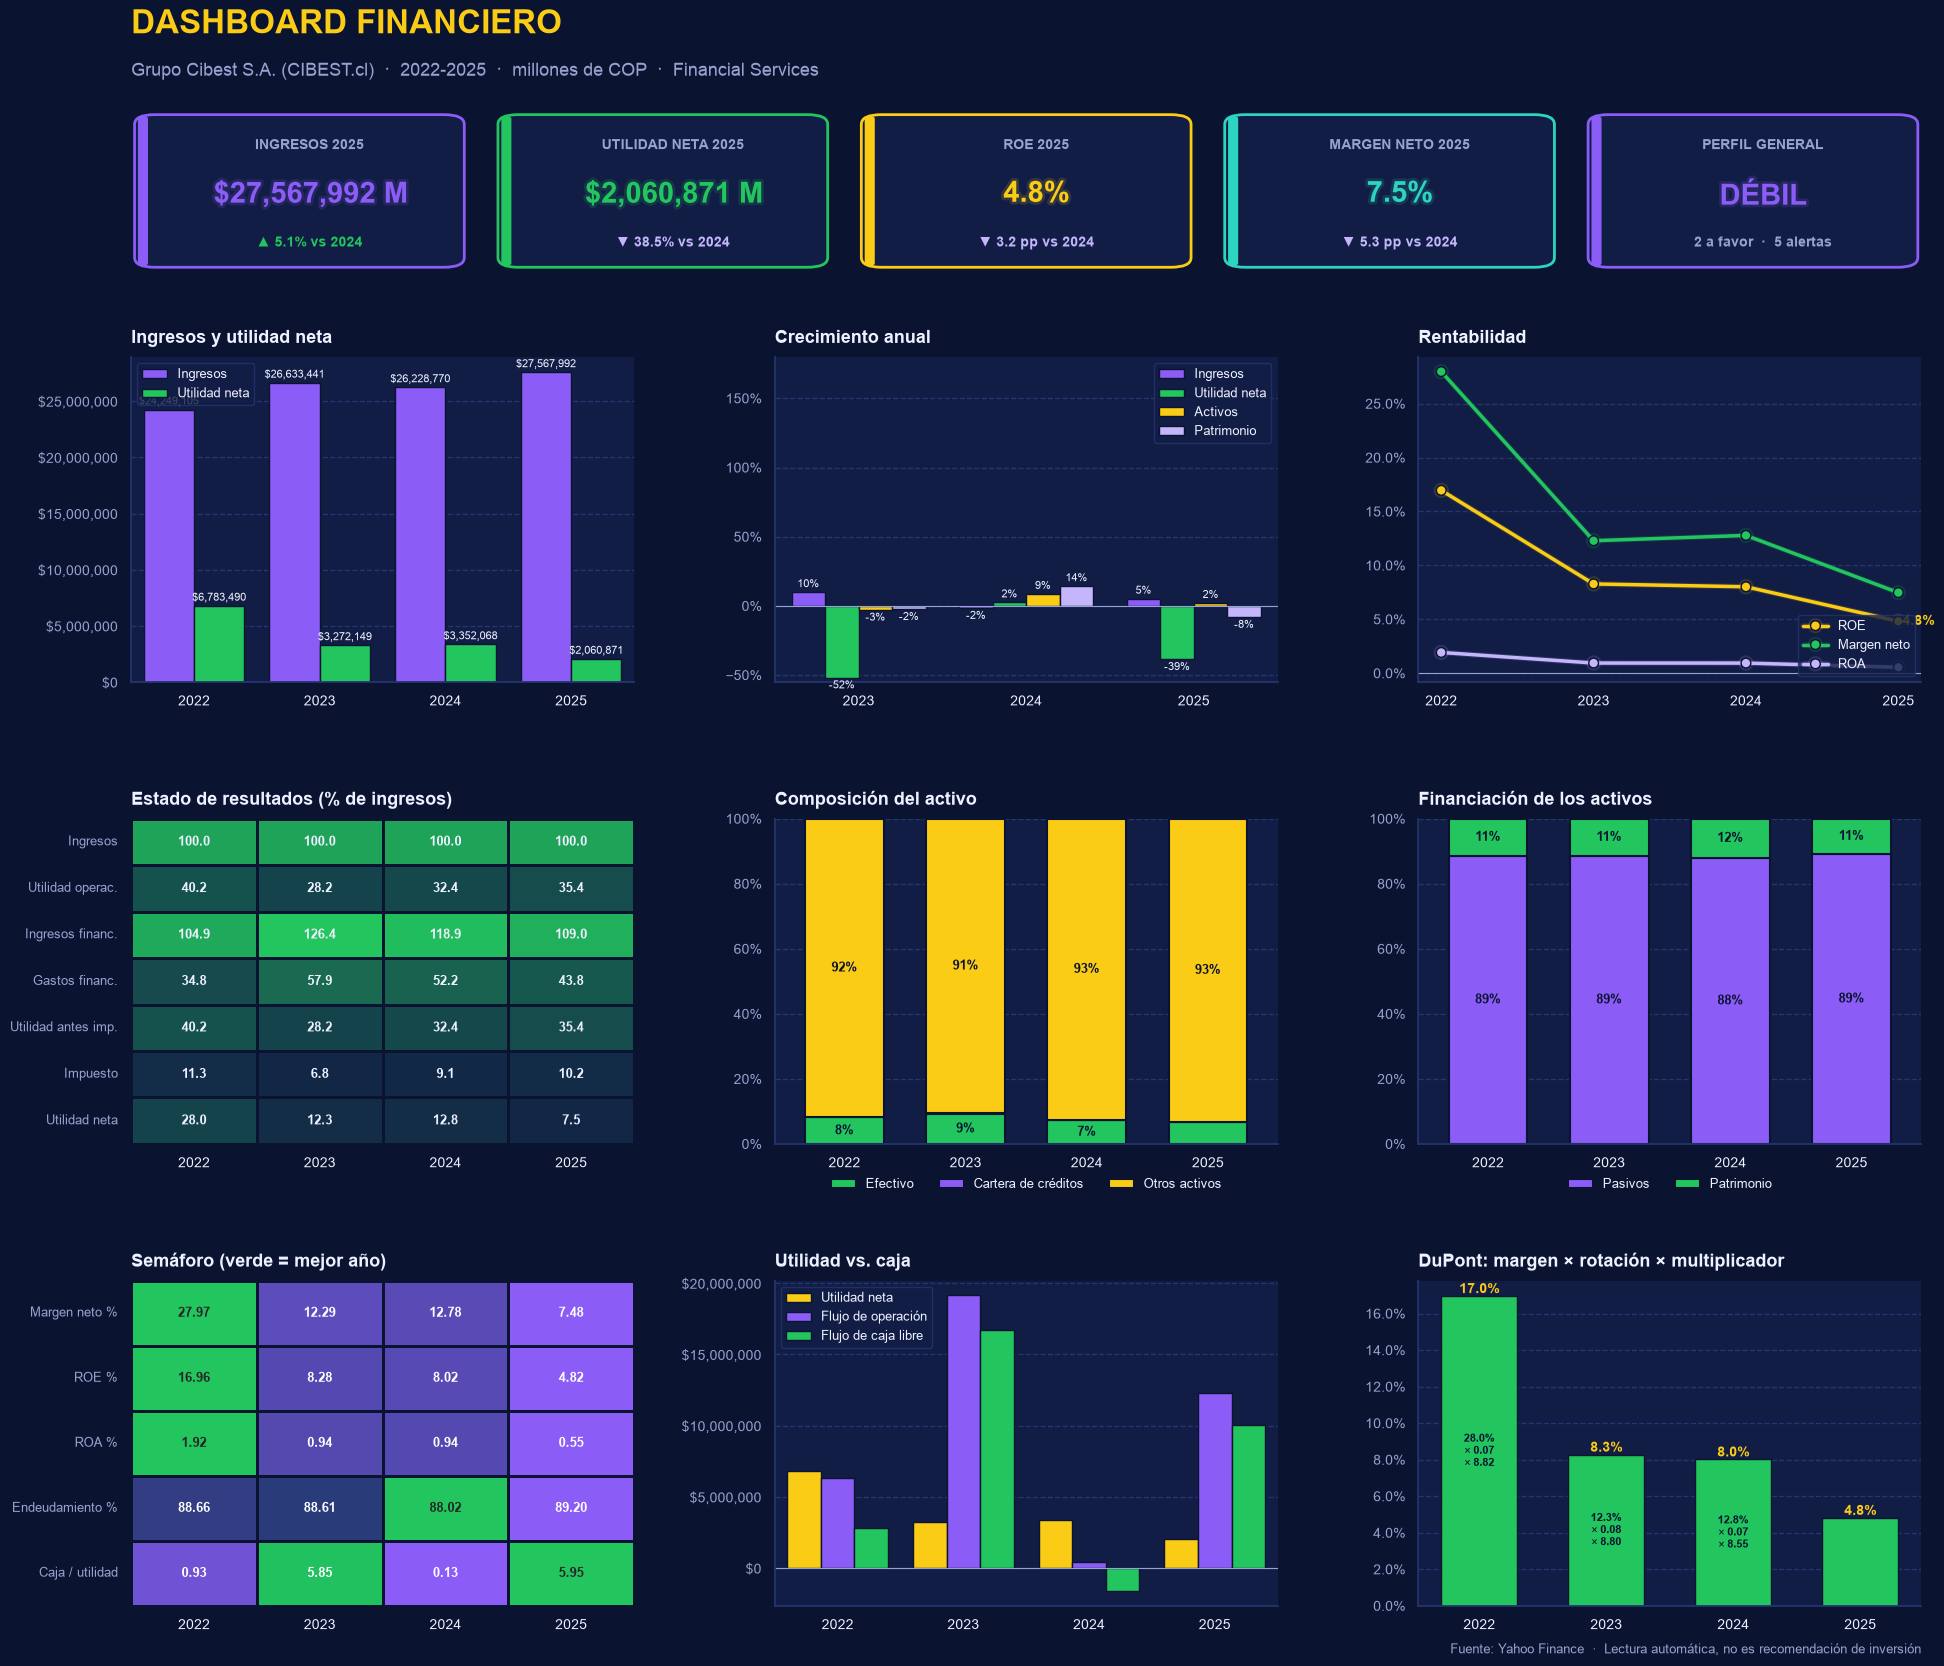

In [35]:
# ---------- 10. DASHBOARD (seaborn: azul marino, morado, amarillo y verde) ----------
fondo = "#0a1330"          # azul marino oscuro
panel = "#111d45"          # azul marino
borde = "#25356e"          # bordes y cuadrícula
texto = "#eef1ff"
tenue = "#97a3cf"
morado = "#8b5cf6"
lila = "#c4b5fd"
amarillo = "#facc15"
verde = "#22c55e"
verde_agua = "#2dd4bf"
azul_medio = "#3b4f9a"

sns.set_theme(style="dark", rc={
    "figure.facecolor": fondo,
    "axes.facecolor": panel,
    "axes.edgecolor": borde,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": borde,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": texto,
    "axes.labelcolor": tenue,
    "xtick.color": texto,
    "ytick.color": tenue,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.titlecolor": texto,
    "legend.facecolor": panel,
    "legend.edgecolor": borde,
    "legend.labelcolor": texto,
    "legend.fontsize": 9,
})
estilo_titulo = {"fontsize": 13, "fontweight": "bold", "loc": "left", "pad": 10}
brillo = lambda color: [efectos.Stroke(linewidth=4, foreground=color, alpha=0.15), efectos.Normal()]
años_txt = [str(año) for año in er.columns]

# Figura: una fila de tarjetas arriba y una cuadrícula de 3 x 3 gráficas abajo
fig = plt.figure(figsize=(20, 17))
rej_general = fig.add_gridspec(2, 1, height_ratios=[0.13, 1], hspace=0.12,
                               left=0.085, right=0.98, top=0.92, bottom=0.04)
rej_tarjetas = rej_general[0].subgridspec(1, 5, wspace=0.08)
rej_graficas = rej_general[1].subgridspec(3, 3, hspace=0.42, wspace=0.28)

fig.text(0.085, 0.965, "DASHBOARD FINANCIERO", fontsize=24, fontweight="bold", color=amarillo)
fig.text(0.085, 0.94, f"{nombre_empresa} ({ticker})  ·  {primero}-{ultimo}  ·  millones de {moneda}  ·  {sector}",
         fontsize=13, color=tenue)
fig.text(0.98, 0.012, "Fuente: Yahoo Finance  ·  Lectura automática, no es recomendación de inversión",
         ha="right", fontsize=9, color=tenue)

# --- Tarjetas (título, valor, color, cambio vs año anterior, unidad del cambio) ---
cambio_roe = ind.loc["ROE (%)", ultimo] - ind.loc["ROE (%)", anterior]
cambio_margen = ind.loc["Margen neto (%)", ultimo] - ind.loc["Margen neto (%)", anterior]
colores_perfil = {"SÓLIDO": verde, "MIXTO": amarillo, "DÉBIL": morado}
tarjetas = [
    (f"Ingresos {ultimo}", f"{dinero(ventas[ultimo] / escala, 0)} M", morado, crec_ult, "%"),
    (f"Utilidad neta {ultimo}", f"{dinero(u_neta[ultimo] / escala, 0)} M", verde, crec_un, "%"),
    (f"ROE {ultimo}", f"{roe_u:.1f}%", amarillo, cambio_roe, " pp"),
    (f"Margen neto {ultimo}", f"{mn_u:.1f}%", verde_agua, cambio_margen, " pp"),
    ("Perfil general", perfil, colores_perfil[perfil], np.nan, ""),
]
for i, (titulo, valor, color, variacion, unidad) in enumerate(tarjetas):
    eje = fig.add_subplot(rej_tarjetas[0, i])
    eje.axis("off")

    # Caja con borde de color y franja lateral
    caja = FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle="round,pad=0.01,rounding_size=0.06",
                          transform=eje.transAxes, facecolor=panel, edgecolor=color, linewidth=2)
    franja = FancyBboxPatch((0.02, 0.04), 0.03, 0.92, boxstyle="round,pad=0,rounding_size=0.015",
                            transform=eje.transAxes, facecolor=color, edgecolor="none")
    eje.add_patch(caja)
    eje.add_patch(franja)

    # Texto de abajo: cambio contra el año anterior
    if titulo == "Perfil general":
        debajo = f"{len(a_favor)} a favor  ·  {len(alertas)} alertas"
        color_debajo = tenue
    elif pd.isna(variacion):
        debajo = ""
        color_debajo = tenue
    elif variacion >= 0:
        debajo = f"▲ {variacion:,.1f}{unidad} vs {anterior}"
        color_debajo = verde
    else:
        debajo = f"▼ {abs(variacion):,.1f}{unidad} vs {anterior}"
        color_debajo = lila

    eje.text(0.53, 0.78, titulo.upper(), ha="center", va="center", fontsize=10,
             color=tenue, fontweight="bold", transform=eje.transAxes)
    eje.text(0.53, 0.48, valor, ha="center", va="center", fontsize=21, fontweight="bold",
             color=color, transform=eje.transAxes, path_effects=brillo(color))
    eje.text(0.53, 0.18, debajo, ha="center", va="center", fontsize=10, fontweight="bold",
             color=color_debajo, transform=eje.transAxes)

# Ejes de las 9 gráficas (3 filas x 3 columnas)
g1 = fig.add_subplot(rej_graficas[0, 0])
g2 = fig.add_subplot(rej_graficas[0, 1])
g3 = fig.add_subplot(rej_graficas[0, 2])
g4 = fig.add_subplot(rej_graficas[1, 0])
g5 = fig.add_subplot(rej_graficas[1, 1])
g6 = fig.add_subplot(rej_graficas[1, 2])
g7 = fig.add_subplot(rej_graficas[2, 0])
g8 = fig.add_subplot(rej_graficas[2, 1])
g9 = fig.add_subplot(rej_graficas[2, 2])

# --- Gráficas 1, 2 y 8: barras agrupadas (eje, título, años, series, colores, unidad) ---
barras_agrupadas = [
    (g1, "Ingresos y utilidad neta", er.columns,
     {"Ingresos": ventas / escala, "Utilidad neta": u_neta / escala},
     [morado, verde], "$"),
    (g2, "Crecimiento anual", h_er.columns,
     {"Ingresos": h_er.loc["Ingresos"], "Utilidad neta": h_er.loc["UTILIDAD NETA"],
      "Activos": h_bg.loc["TOTAL ACTIVOS"], "Patrimonio": h_bg.loc["TOTAL PATRIMONIO"]},
     [morado, verde, amarillo, lila], "%"),
    (g8, "Utilidad vs. caja", er.columns,
     {"Utilidad neta": u_neta / escala, "Flujo de operación": f_oper / escala, "Flujo de caja libre": fcl / escala},
     [amarillo, morado, verde], "$"),
]
tope_crecimiento = 150                       # en g2, las barras mayores a 150 % se cortan para no aplastar las demás
for eje, titulo, años, series, colores, unidad in barras_agrupadas:
    # Tabla larga para seaborn: una fila por año y cuenta
    datos = pd.DataFrame(series)
    datos.index = [str(año) for año in años]
    datos = datos.reset_index(names="Año")
    datos = datos.melt(id_vars="Año", var_name="Cuenta", value_name="Valor")
    valores_reales = datos["Valor"].copy()
    if unidad == "%":
        datos["Valor"] = datos["Valor"].clip(upper=tope_crecimiento)
    sns.barplot(data=datos, x="Año", y="Valor", hue="Cuenta", palette=colores,
                saturation=1, edgecolor=fondo, ax=eje)

    # Etiquetas de valor encima de cada barra (en g8 se saturaría)
    # En % se muestra el valor real; si la barra está cortada, la etiqueta lleva "▲"
    if eje is not g8:
        for barras, cuenta in zip(eje.containers, datos["Cuenta"].unique()):
            reales = valores_reales[datos["Cuenta"] == cuenta].values
            if unidad == "$":
                etiquetas = [dinero(real, 0) for real in reales]
            else:
                etiquetas = [f"▲{real:.0f}%" if real > tope_crecimiento else f"{real:.0f}%" for real in reales]
            eje.bar_label(barras, labels=etiquetas, fontsize=8, color=texto, padding=2)
    if unidad == "%":
        eje.set_ylim(top=tope_crecimiento * 1.2)

    # Formato del eje Y
    if unidad == "$":
        eje.yaxis.set_major_formatter(FuncFormatter(lambda v, p: dinero(v, 0)))
    else:
        eje.yaxis.set_major_formatter(PercentFormatter())
    eje.set_xlabel("")
    eje.set_ylabel("")
    eje.axhline(0, color=tenue, linewidth=0.8)
    eje.set_title(titulo, **estilo_titulo)
    if unidad == "%":
        eje.legend(title="", loc="upper right")
    else:
        eje.legend(title="", loc="upper left")

# --- Gráfica 3: rentabilidad (líneas con brillo) ---
lineas = {"ROE": ("ROE (%)", amarillo), "Margen neto": ("Margen neto (%)", verde), "ROA": ("ROA (%)", lila)}
if not es_fin:                                  # en financieras estos márgenes no aplican
    lineas["Margen operacional"] = ("Margen operacional (%)", morado)
    lineas["Margen EBITDA"] = ("Margen EBITDA (%)", verde_agua)
for nombre_linea, (fila, color) in lineas.items():
    g3.plot(años_txt, ind.loc[fila].values, color=color, marker="o", linewidth=2.5, markersize=7,
            markeredgecolor=fondo, path_effects=brillo(color), label=nombre_linea)
g3.text(len(años_txt) - 1, ind.loc["ROE (%)", ultimo], f" {ind.loc['ROE (%)', ultimo]:.1f}%",
        va="center", fontsize=10, fontweight="bold", color=amarillo)
g3.axhline(0, color=tenue, linewidth=0.8)
g3.yaxis.set_major_formatter(PercentFormatter())
g3.set_title("Rentabilidad", **estilo_titulo)
g3.legend(loc="lower right")

# --- Gráfica 4: estado de resultados vertical (mapa de calor, con nombres cortos) ---
nombres_cortos = {
    "Ingresos": "Ingresos",
    "Costo de ventas": "Costo de ventas",
    "UTILIDAD BRUTA": "Utilidad bruta",
    "Gastos operacionales": "Gastos operac.",
    "UTILIDAD OPERACIONAL": "Utilidad operac.",
    "Ingresos financieros": "Ingresos financ.",
    "Gastos financieros": "Gastos financ.",
    "UTILIDAD ANTES DE IMPUESTOS": "Utilidad antes imp.",
    "Impuesto de renta": "Impuesto",
    "UTILIDAD NETA": "Utilidad neta",
}
vertical_corto = v_er.rename(index=nombres_cortos, columns=str)
cmap_vertical = LinearSegmentedColormap.from_list("vertical", [morado, panel, verde])
sns.heatmap(vertical_corto, annot=True, fmt=".1f", center=0, cbar=False,
            linewidths=2, linecolor=fondo, cmap=cmap_vertical,
            annot_kws={"fontsize": 9, "fontweight": "bold", "color": texto}, ax=g4)
g4.set_xlabel("")
g4.set_ylabel("")
g4.tick_params(axis="y", labelsize=9)
g4.set_title("Estado de resultados (% de ingresos)", **estilo_titulo)

# --- Gráficas 5 y 6: barras apiladas como % del activo ---
otros_corrientes = ac.fillna(0) - efectivo.fillna(0) - cartera.fillna(0) - inventario
otros_corrientes = otros_corrientes.clip(lower=0)
composicion = pd.DataFrame({
    "Efectivo": efectivo.fillna(0),
    "Cuentas por cobrar": cartera.fillna(0),
    "Inventarios": inventario,
    "Otros corrientes": otros_corrientes,
    "No corriente": at - ac.fillna(0),
})
if es_fin:                                     # financieras: sin corriente / no corriente
    composicion = pd.DataFrame({
        "Efectivo": efectivo.fillna(0),
        "Cartera de créditos": cartera.fillna(0),
        "Otros activos": (at - efectivo.fillna(0) - cartera.fillna(0)).clip(lower=0),
    })
composicion = composicion.div(at, axis=0) * 100
financiacion = pd.DataFrame({
    "Pasivo corriente": pc,
    "Pasivo no corriente": pt - pc,
    "Patrimonio": patrimonio,
})
if es_fin:
    financiacion = pd.DataFrame({
        "Pasivos": pt,
        "Patrimonio": patrimonio,
    })
financiacion = financiacion.div(at, axis=0) * 100

barras_apiladas = [
    (g5, "Composición del activo", composicion, [verde, morado, amarillo, lila, azul_medio]),
    (g6, "Financiación de los activos", financiacion, [lila, morado, verde][-len(financiacion.columns):]),
]
for eje, titulo, tabla_apilada, colores in barras_apiladas:
    tabla_apilada = tabla_apilada.fillna(0)
    tabla_apilada.index = años_txt
    usadas = tabla_apilada.sum() > 0                       # quitamos lo que la empresa no tiene
    colores_usados = [color for color, usada in zip(colores, usadas) if usada]
    tabla_apilada = tabla_apilada.loc[:, usadas]
    tabla_apilada.plot(kind="bar", stacked=True, ax=eje, width=0.65, rot=0,
                       edgecolor=fondo, linewidth=1.5, color=colores_usados)
    for barras in eje.containers:                          # % dentro de cada bloque si es visible
        etiquetas = [f"{b.get_height():.0f}%" if b.get_height() >= 7 else "" for b in barras]
        eje.bar_label(barras, labels=etiquetas, label_type="center", fontsize=9, color=fondo, fontweight="bold")
    eje.yaxis.set_major_formatter(PercentFormatter())
    eje.set_ylim(0, 100)
    eje.set_xlabel("")
    eje.set_title(titulo, **estilo_titulo)
    eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, frameon=False)

# --- Gráfica 7: semáforo de indicadores (verde = mejor año) ---
# 1 = más alto es mejor, -1 = más bajo es mejor
semaforo = {"Margen neto (%)": 1, "ROE (%)": 1, "ROA (%)": 1, "Endeudamiento (%)": -1,
            "Flujo operación / Utilidad neta (veces)": 1}
if not es_fin:
    semaforo["Razón corriente (veces)"] = 1
    semaforo["Cobertura de intereses (veces)"] = 1
    semaforo["Deuda neta / EBITDA (veces)"] = -1
    semaforo["Ciclo de efectivo (días)"] = -1
nombres_semaforo = {
    "Margen neto (%)": "Margen neto %",
    "ROE (%)": "ROE %",
    "ROA (%)": "ROA %",
    "Endeudamiento (%)": "Endeudamiento %",
    "Flujo operación / Utilidad neta (veces)": "Caja / utilidad",
    "Razón corriente (veces)": "Razón corriente",
    "Cobertura de intereses (veces)": "Cobertura int.",
    "Deuda neta / EBITDA (veces)": "Deuda neta/EBITDA",
    "Ciclo de efectivo (días)": "Ciclo efectivo (días)",
}
tabla = ind.reindex(list(semaforo)).dropna(how="all")
direccion = pd.Series(semaforo).reindex(tabla.index)
puntaje = tabla.mul(direccion, axis=0)                     # así, más alto siempre es mejor
minimo = puntaje.min(axis=1)
rango = (puntaje.max(axis=1) - minimo).replace(0, np.nan)
puntaje = puntaje.sub(minimo, axis=0).div(rango, axis=0)   # 0 = peor año, 1 = mejor año
puntaje = puntaje.fillna(0.5)
cmap_semaforo = LinearSegmentedColormap.from_list("semaforo", [morado, "#2a3a7a", verde])
sns.heatmap(puntaje.rename(index=nombres_semaforo, columns=str), annot=tabla.rename(index=nombres_semaforo, columns=str),
            fmt=".2f", vmin=0, vmax=1, cbar=False, linewidths=2, linecolor=fondo, cmap=cmap_semaforo,
            annot_kws={"fontsize": 9, "fontweight": "bold"}, ax=g7)
g7.set_xlabel("")
g7.set_ylabel("")
g7.tick_params(axis="y", labelsize=9)
g7.set_title("Semáforo (verde = mejor año)", **estilo_titulo)

# --- Gráfica 9: DuPont (ROE con sus tres componentes dentro de la barra) ---
roe = ind.loc["ROE (%)"]
colores_roe = [verde if valor >= 0 else morado for valor in roe.fillna(0)]
g9.bar(años_txt, roe.values, color=colores_roe, edgecolor=fondo, width=0.6)
for i, año in enumerate(er.columns):
    margen = ind.loc["Margen neto (%)", año]
    rotacion = ind.loc["DuPont - Rotación de activos (veces)", año]
    multiplicador = ind.loc["DuPont - Multiplicador de capital (veces)", año]
    posicion_valor = "bottom" if roe[año] >= 0 else "top"
    if abs(roe[año]) >= 8:                                 # solo si la barra es lo bastante alta
        g9.text(i, roe[año] / 2, f"{margen:.1f}%\n× {rotacion:.2f}\n× {multiplicador:.2f}",
                ha="center", va="center", fontsize=8, color=fondo, fontweight="bold")
    g9.text(i, roe[año], f"{roe[año]:.1f}%", ha="center", va=posicion_valor,
            fontsize=10, fontweight="bold", color=amarillo)
g9.axhline(0, color=tenue, linewidth=0.8)
g9.yaxis.set_major_formatter(PercentFormatter())
g9.set_title("DuPont: margen × rotación × multiplicador", **estilo_titulo)

plt.savefig(f"dashboard_{archivo}.png", dpi=120, facecolor=fondo)
plt.show()